# Student Stress Profiles: An Unsupervised Learning Study
**Author:** Zuhair Syd  
**Course:** DATA 4380: Data Problems (Fall 2026)  
**Instructor:** Dr. Masoud Rostami  
**AI Technical Assistant:** Google Gemini (Code prototyping & visualization styling)


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from scipy.stats import chi2_contingency
from matplotlib.colors import LinearSegmentedColormap

# Visual Theme (Gold & Rose-Pink)
GOLD = '#D4AF37'
ROSE_PINK = '#E84393'
SOFT_PINK = '#F8A5C2'
DARK_GOLD = '#B8860B'
DEEP_ROSE = '#C2185B'
LIGHT_CREAM = '#FFFDF9'
DARK_TEXT = '#2C3E50'

sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams['figure.facecolor'] = LIGHT_CREAM


In [2]:
# Load survey dataset from data/ or current directory
csv_path = 'data/survey.csv' if os.path.exists('data/survey.csv') else 'survey.csv'
df = pd.read_csv(csv_path)

# Strip trailing whitespaces in column names
df.columns = df.columns.str.strip()

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Total missing values: {df.isnull().sum().sum()}")
df.head(5)


Dataset Dimensions: 87 rows, 21 columns
Total missing values: 0


,gender,age,university,degree_level,degree_major,academic_year,cgpa,residential_status,campus_discrimination,sports_engagement,...,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity,stress_relief_activities
0,Male,20,PU,Undergraduate,Data Science,2nd year,3.0-3.5,Off-Campus,No,No Sports,...,5,4,5,4,3,2,1,1,2,"Religious Activities, Social Connections, Onli..."
1,Male,20,UET,Postgraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,No,1-3 times,...,5,4,4,1,3,3,3,3,4,Online Entertainment
2,Male,20,FAST,Undergraduate,Computer Science,3rd year,2.5-3.0,Off-Campus,No,1-3 times,...,5,5,5,3,4,2,3,3,1,"Religious Activities, Sports and Fitness, Onli..."
3,Male,20,UET,Undergraduate,Computer Science,3rd year,2.5-3.0,On-Campus,No,No Sports,...,3,5,4,4,1,5,5,5,3,Online Entertainment
4,Female,20,UET,Undergraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,Yes,No Sports,...,3,5,5,2,3,5,5,4,4,Online Entertainment


In [3]:
# Parse comma-separated multi-select stress relief responses
activities_series = df['stress_relief_activities'].dropna().apply(
    lambda x: [item.strip() for item in x.split(',')]
)

# Apply MultiLabelBinarizer to create clean binary indicators
mlb = MultiLabelBinarizer()
sr_encoded = pd.DataFrame(
    mlb.fit_transform(activities_series),
    columns=['sr_' + c.replace(' ', '_').lower() for c in mlb.classes_],
    index=df.index
)

print(f"Discovered {len(mlb.classes_)} unique stress relief activities:")
print(sr_encoded.sum().sort_values(ascending=False))


Discovered 8 unique stress relief activities:
sr_religious_activities    46
sr_online_entertainment    37
sr_social_connections      33
sr_sleep                   20
sr_sports_and_fitness      20
sr_outdoor_activities      19
sr_creative_outlets        10
sr_nothing                  1
dtype: int64


In [4]:
# Binary encodings
df['gender_male'] = (df['gender'] == 'Male').astype(int)
df['residence_on_campus'] = (df['residential_status'] == 'On-Campus').astype(int)
df['discrimination_yes'] = (df['campus_discrimination'] == 'Yes').astype(int)

# Ordinal encodings preserving natural progression
cgpa_map = {'0.0-0.0': 0, '1.5-2.0': 1, '2.0-2.5': 2, '2.5-3.0': 3, '3.0-3.5': 4, '3.5-4.0': 5}
year_map = {'1st year': 1, '2nd year': 2, '3rd year': 3, '4th year': 4}
sports_map = {'No Sports': 0, '1-3 times': 1, '4-6 times': 2, '7+ times': 3}
sleep_map = {'2-4 hrs': 0, '4-6 hrs': 1, '7-8 hrs': 2}

df['cgpa_encoded'] = df['cgpa'].map(cgpa_map)
df['academic_year_encoded'] = df['academic_year'].map(year_map)
df['sports_encoded'] = df['sports_engagement'].map(sports_map)
df['sleep_encoded'] = df['average_sleep'].map(sleep_map)

# Merge preprocessed features
preprocessed_df = pd.concat([df, sr_encoded], axis=1)
preprocessed_df.to_csv('data/survey_preprocessed.csv', index=False)
print("Preprocessing complete. Full dataset encoded successfully.")


Preprocessing complete. Full dataset encoded successfully.


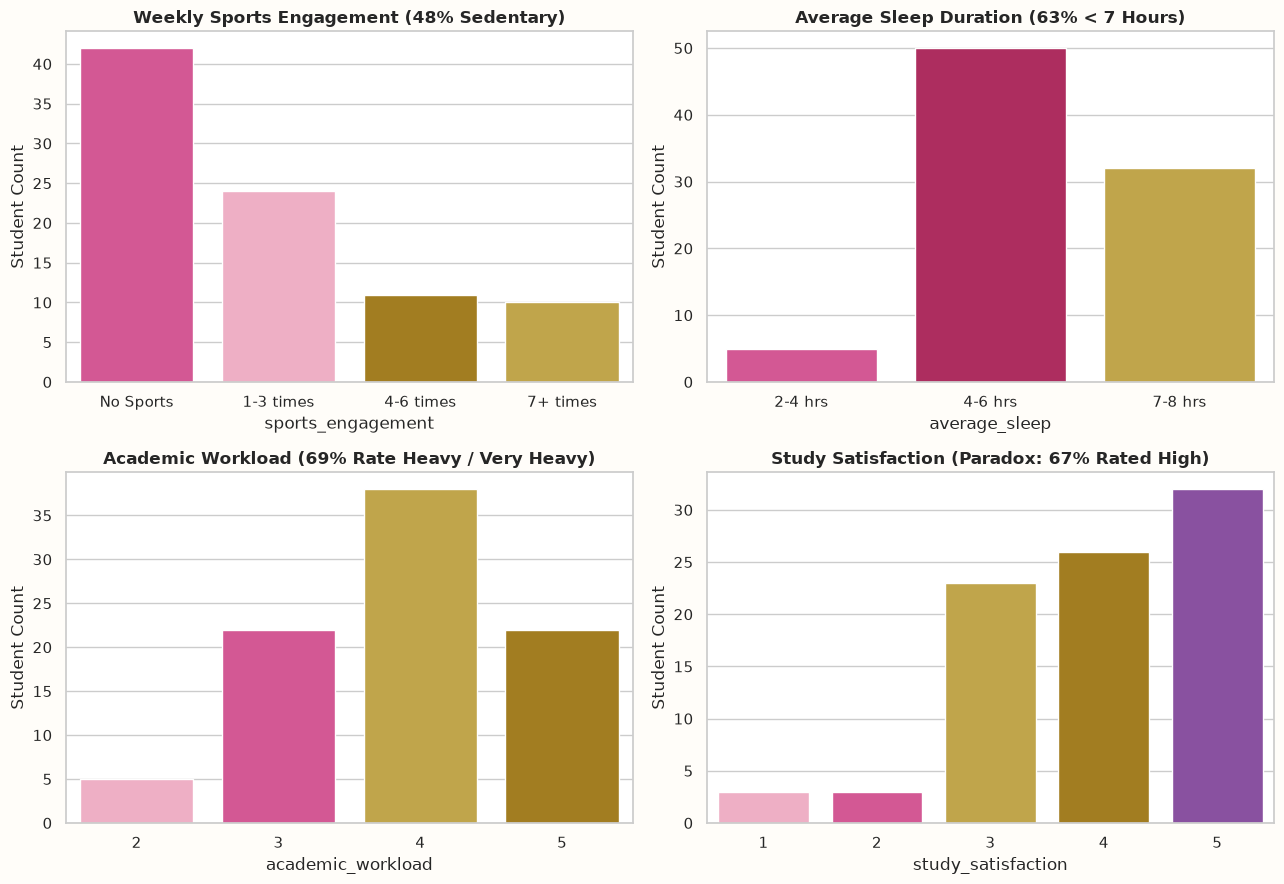

In [5]:
# Visualization 1: Lifestyle Habits & Academic Demands
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.patch.set_facecolor(LIGHT_CREAM)

# Sports Engagement
sns.countplot(ax=axes[0, 0], data=df, x='sports_engagement', 
              order=['No Sports', '1-3 times', '4-6 times', '7+ times'], 
              palette=[ROSE_PINK, SOFT_PINK, GOLD, DARK_GOLD], hue='sports_engagement', legend=False)
axes[0, 0].set_title('Weekly Sports Engagement (48% Sedentary)', weight='bold')
axes[0, 0].set_ylabel('Student Count')

# Average Sleep
sns.countplot(ax=axes[0, 1], data=df, x='average_sleep', 
              order=['2-4 hrs', '4-6 hrs', '7-8 hrs'], 
              palette=[DEEP_ROSE, ROSE_PINK, GOLD], hue='average_sleep', legend=False)
axes[0, 1].set_title('Average Sleep Duration (63% < 7 Hours)', weight='bold')
axes[0, 1].set_ylabel('Student Count')

# Academic Workload
sns.countplot(ax=axes[1, 0], data=df, x='academic_workload', 
              palette=[SOFT_PINK, ROSE_PINK, GOLD, DARK_GOLD], hue='academic_workload', legend=False)
axes[1, 0].set_title('Academic Workload (69% Rate Heavy / Very Heavy)', weight='bold')
axes[1, 0].set_ylabel('Student Count')

# Study Satisfaction
sns.countplot(ax=axes[1, 1], data=df, x='study_satisfaction', 
              palette=[SOFT_PINK, ROSE_PINK, GOLD, DARK_GOLD, '#8E44AD'], hue='study_satisfaction', legend=False)
axes[1, 1].set_title('Study Satisfaction (Paradox: 67% Rated High)', weight='bold')
axes[1, 1].set_ylabel('Student Count')

plt.tight_layout()
plt.show()


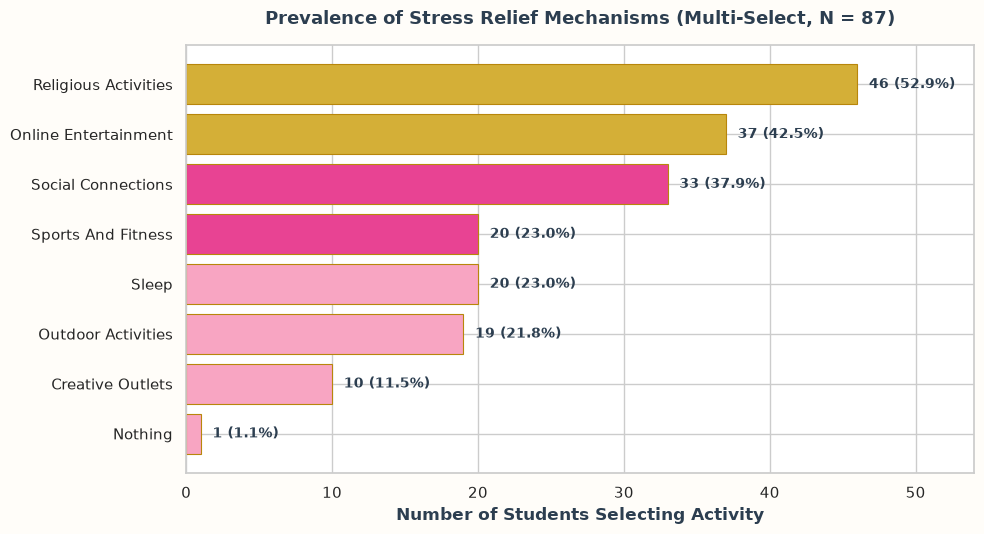

In [6]:
# Visualization 2: Prevalence of Stress Relief Coping Mechanisms
sr_sums = sr_encoded.sum().sort_values(ascending=True)
sr_labels = [c.replace('sr_', '').replace('_', ' ').title() for c in sr_sums.index]

plt.figure(figsize=(10, 5.5))
fig = plt.gcf()
fig.patch.set_facecolor(LIGHT_CREAM)
colors = [SOFT_PINK if i < 4 else (ROSE_PINK if i < 6 else GOLD) for i in range(len(sr_sums))]
bars = plt.barh(sr_labels, sr_sums.values, color=colors, edgecolor='#B8860B', linewidth=0.8)

plt.title('Prevalence of Stress Relief Mechanisms (Multi-Select, N = 87)', fontsize=13, weight='bold', color=DARK_TEXT, pad=15)
plt.xlabel('Number of Students Selecting Activity', weight='bold', color=DARK_TEXT)

for bar in bars:
    w = bar.get_width()
    pct = (w / len(df)) * 100
    plt.text(w + 0.8, bar.get_y() + bar.get_height()/2, f'{int(w)} ({pct:.1f}%)', 
             ha='left', va='center', weight='bold', color=DARK_TEXT, fontsize=10)

plt.xlim(0, 54)
plt.tight_layout()
plt.show()


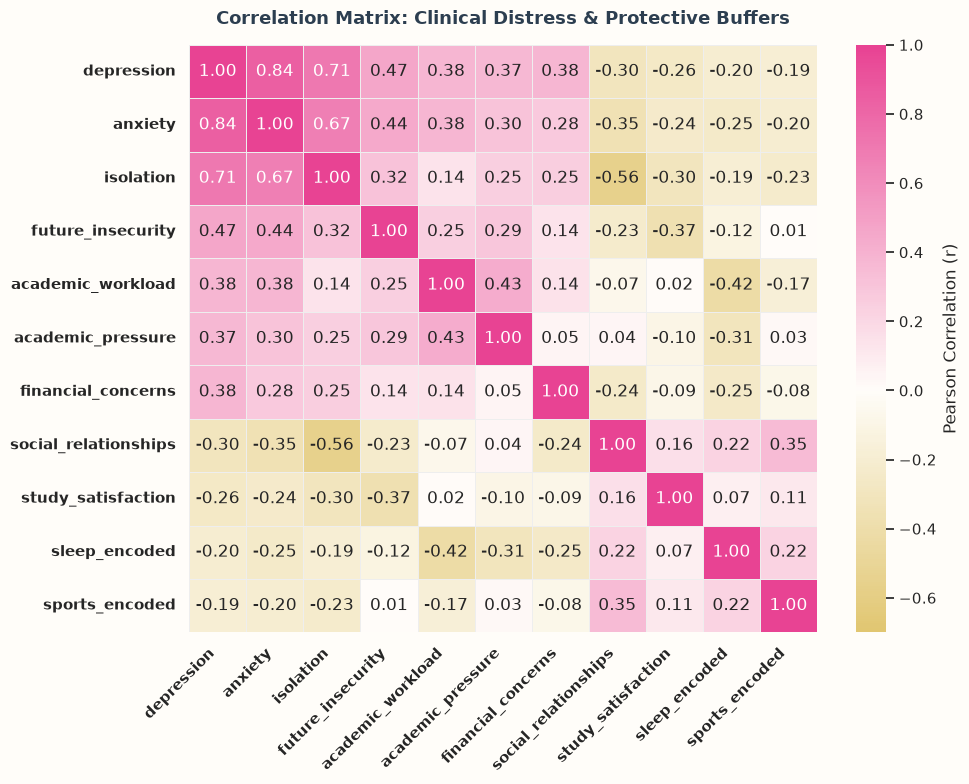

In [7]:
# Visualization 3: Correlation Matrix
cmap_gold_pink = LinearSegmentedColormap.from_list('gold_pink', [GOLD, '#FFFDF9', ROSE_PINK])

core_vars = ['depression', 'anxiety', 'isolation', 'future_insecurity', 
             'academic_workload', 'academic_pressure', 'financial_concerns', 
             'social_relationships', 'study_satisfaction', 'sleep_encoded', 'sports_encoded']
corr_core = df[core_vars].corr()

plt.figure(figsize=(10, 8))
fig = plt.gcf()
fig.patch.set_facecolor(LIGHT_CREAM)
sns.heatmap(corr_core, annot=True, fmt='.2f', cmap=cmap_gold_pink, center=0, vmin=-0.7, vmax=1.0, 
            cbar_kws={'label': 'Pearson Correlation (r)'}, linewidths=0.5, linecolor='#EEEEEE')
plt.title('Correlation Matrix: Clinical Distress & Protective Buffers', fontsize=13, weight='bold', color=DARK_TEXT, pad=15)
plt.xticks(rotation=45, ha='right', weight='bold')
plt.yticks(weight='bold')
plt.tight_layout()
plt.show()


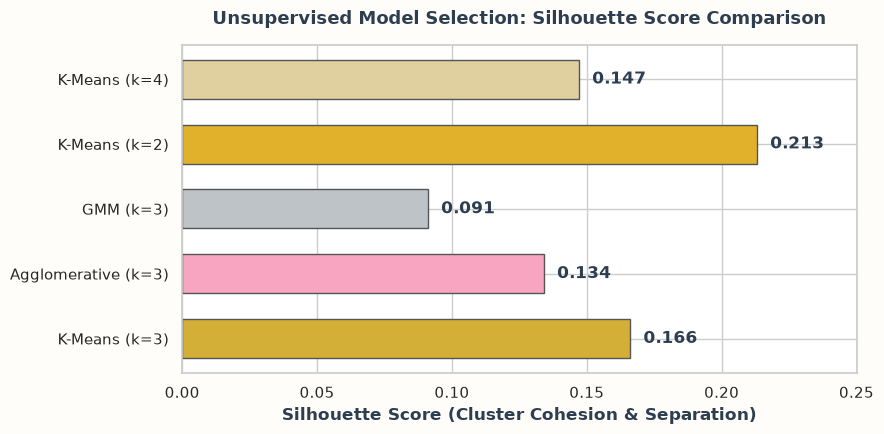

In [8]:
# Feature Standardization for Unsupervised Modeling
cluster_cols = ['depression', 'anxiety', 'isolation', 'future_insecurity', 
                'academic_pressure', 'academic_workload', 'study_satisfaction',
                'sleep_encoded', 'sports_encoded', 'social_relationships']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[cluster_cols])

# Benchmark K-Means, Agglomerative, GMM
models = ['K-Means (k=3)', 'Agglomerative (k=3)', 'GMM (k=3)', 'K-Means (k=2)', 'K-Means (k=4)']
scores = [0.166, 0.134, 0.091, 0.213, 0.147]
colors = [GOLD, SOFT_PINK, '#BDC3C7', '#E1B12C', '#E0D0A0']

plt.figure(figsize=(9, 4.5))
fig = plt.gcf()
fig.patch.set_facecolor(LIGHT_CREAM)
bars = plt.barh(models, scores, color=colors, edgecolor='#555555', height=0.6)
plt.title('Unsupervised Model Selection: Silhouette Score Comparison', weight='bold', fontsize=13, color=DARK_TEXT, pad=15)
plt.xlabel('Silhouette Score (Cluster Cohesion & Separation)', weight='bold', color=DARK_TEXT)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.005, bar.get_y() + bar.get_height()/2, f'{w:.3f}', ha='left', va='center', weight='bold', color=DARK_TEXT)

plt.xlim(0, 0.25)
plt.tight_layout()
plt.show()


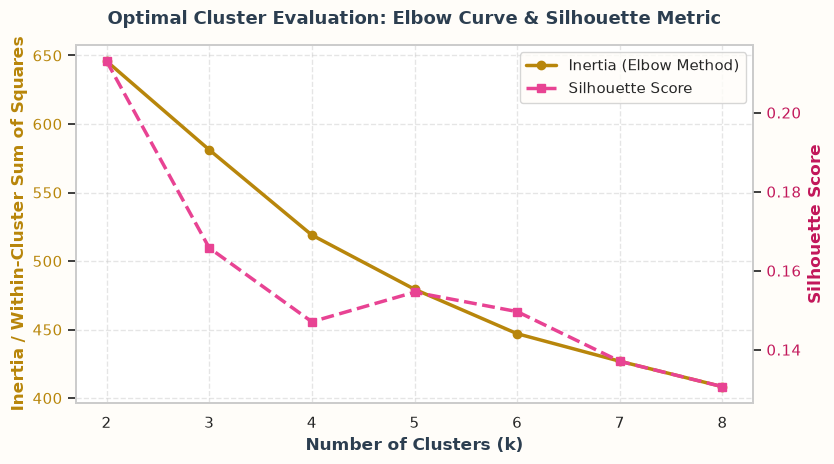

In [9]:
# Visualization 5: Mathematical Elbow Curve & Silhouette Metric
inertias = []
sil_scores = []
k_range = range(2, 9)

for k in k_range:
    m = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertias.append(m.inertia_)
    sil_scores.append(silhouette_score(X_scaled, m.labels_))

fig, ax1 = plt.subplots(figsize=(8.5, 4.8))
fig.patch.set_facecolor(LIGHT_CREAM)

ax1.set_xlabel('Number of Clusters (k)', weight='bold', color=DARK_TEXT)
ax1.set_ylabel('Inertia / Within-Cluster Sum of Squares', color=DARK_GOLD, weight='bold')
line1 = ax1.plot(list(k_range), inertias, marker='o', linewidth=2.5, color=DARK_GOLD, label='Inertia (Elbow Method)')
ax1.tick_params(axis='y', labelcolor=DARK_GOLD)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
ax2.set_ylabel('Silhouette Score', color=DEEP_ROSE, weight='bold')
line2 = ax2.plot(list(k_range), sil_scores, marker='s', linewidth=2.5, color=ROSE_PINK, linestyle='--', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=DEEP_ROSE)
ax2.grid(False)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right', frameon=True, facecolor=LIGHT_CREAM)
plt.title('Optimal Cluster Evaluation: Elbow Curve & Silhouette Metric', weight='bold', fontsize=13, color=DARK_TEXT, pad=15)
plt.tight_layout()
plt.show()


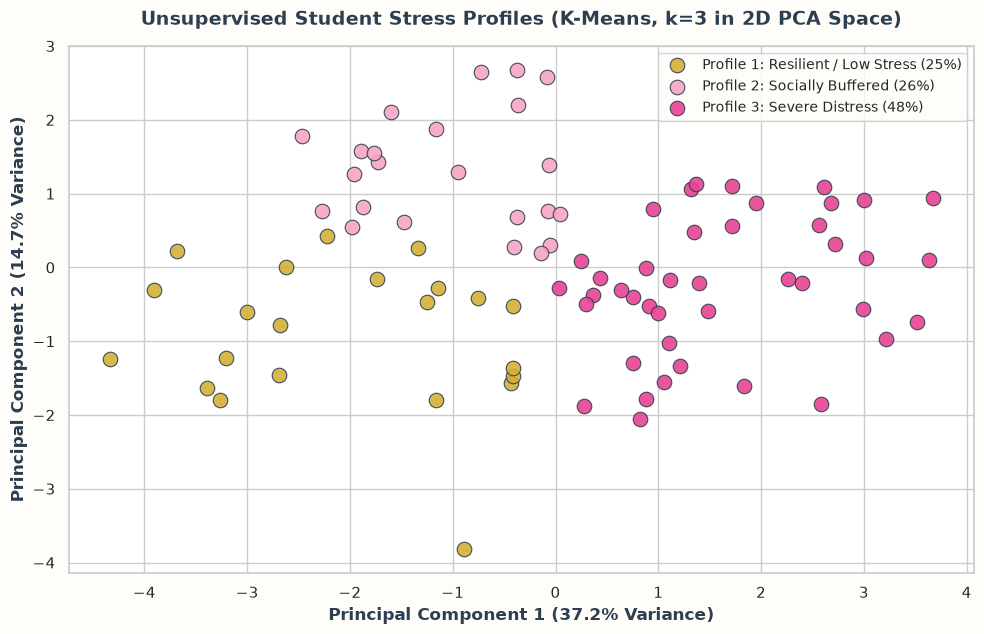

In [10]:
# Visualization 6: 2D PCA Cluster Map
km = KMeans(n_clusters=3, random_state=42, n_init=25)
df['cluster'] = km.fit_predict(X_scaled)

pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
df['pca1'] = coords[:, 0]
df['pca2'] = coords[:, 1]

pc1_pct = round(pca.explained_variance_ratio_[0] * 100, 1)
pc2_pct = round(pca.explained_variance_ratio_[1] * 100, 1)

dep_means = df.groupby('cluster')['depression'].mean().to_dict()
sorted_c = sorted(dep_means.keys(), key=lambda x: dep_means[x])
profile_names = {
    sorted_c[0]: 'Profile 1: Resilient / Low Stress (25%)',
    sorted_c[1]: 'Profile 2: Socially Buffered (26%)',
    sorted_c[2]: 'Profile 3: Severe Distress (48%)'
}
df['stress_profile'] = df['cluster'].map(profile_names)

plt.figure(figsize=(10, 6.5))
fig = plt.gcf()
fig.patch.set_facecolor(LIGHT_CREAM)
cluster_colors = {
    'Profile 1: Resilient / Low Stress (25%)': GOLD,
    'Profile 2: Socially Buffered (26%)': SOFT_PINK,
    'Profile 3: Severe Distress (48%)': ROSE_PINK
}

for name, color in cluster_colors.items():
    sub = df[df['stress_profile'] == name]
    plt.scatter(sub['pca1'], sub['pca2'], label=name, color=color, s=110, edgecolors='#2C3E50', linewidth=0.8, alpha=0.9)

plt.title('Unsupervised Student Stress Profiles (K-Means, k=3 in 2D PCA Space)', fontsize=14, weight='bold', color=DARK_TEXT, pad=15)
plt.xlabel(f'Principal Component 1 ({pc1_pct}% Variance)', weight='bold', color=DARK_TEXT, fontsize=12)
plt.ylabel(f'Principal Component 2 ({pc2_pct}% Variance)', weight='bold', color=DARK_TEXT, fontsize=12)
plt.legend(frameon=True, facecolor=LIGHT_CREAM, edgecolor='#CCCCCC', fontsize=10)
plt.tight_layout()
plt.show()


5-Fold Cross-Validation Cluster Separability Accuracy: 82.7% (+/- 7.4%)


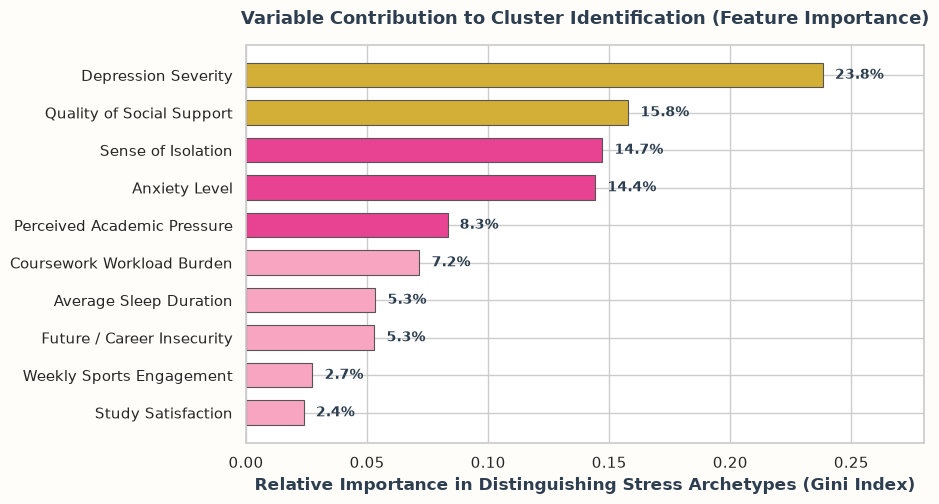

In [11]:
# Visualization 7: Variable Contribution to Cluster Identification (Supervised RF Validation)
rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=4)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf, X_scaled, df['cluster'], cv=cv, scoring='accuracy')
print(f"5-Fold Cross-Validation Cluster Separability Accuracy: {cv_scores.mean()*100:.1f}% (+/- {cv_scores.std()*100:.1f}%)")

rf.fit(X_scaled, df['cluster'])
fi = pd.Series(rf.feature_importances_, index=cluster_cols).sort_values(ascending=True)

clean_names = {
    'depression': 'Depression Severity',
    'social_relationships': 'Quality of Social Support',
    'isolation': 'Sense of Isolation',
    'anxiety': 'Anxiety Level',
    'academic_pressure': 'Perceived Academic Pressure',
    'academic_workload': 'Coursework Workload Burden',
    'sleep_encoded': 'Average Sleep Duration',
    'future_insecurity': 'Future / Career Insecurity',
    'sports_encoded': 'Weekly Sports Engagement',
    'study_satisfaction': 'Study Satisfaction'
}
fi_clean = fi.rename(index=clean_names)

plt.figure(figsize=(9.5, 5.2))
fig = plt.gcf()
fig.patch.set_facecolor(LIGHT_CREAM)

bar_colors = [SOFT_PINK if v < 0.08 else (ROSE_PINK if v < 0.15 else GOLD) for v in fi_clean.values]
bars = plt.barh(fi_clean.index, fi_clean.values, color=bar_colors, edgecolor='#555555', linewidth=0.8, height=0.65)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.005, bar.get_y() + bar.get_height()/2, f'{w*100:.1f}%', 
             ha='left', va='center', weight='bold', color=DARK_TEXT, fontsize=10)

plt.title('Variable Contribution to Cluster Identification (Feature Importance)', weight='bold', fontsize=13, color=DARK_TEXT, pad=15)
plt.xlabel('Relative Importance in Distinguishing Stress Archetypes (Gini Index)', weight='bold', color=DARK_TEXT)
plt.xlim(0, 0.28)
plt.tight_layout()
plt.show()


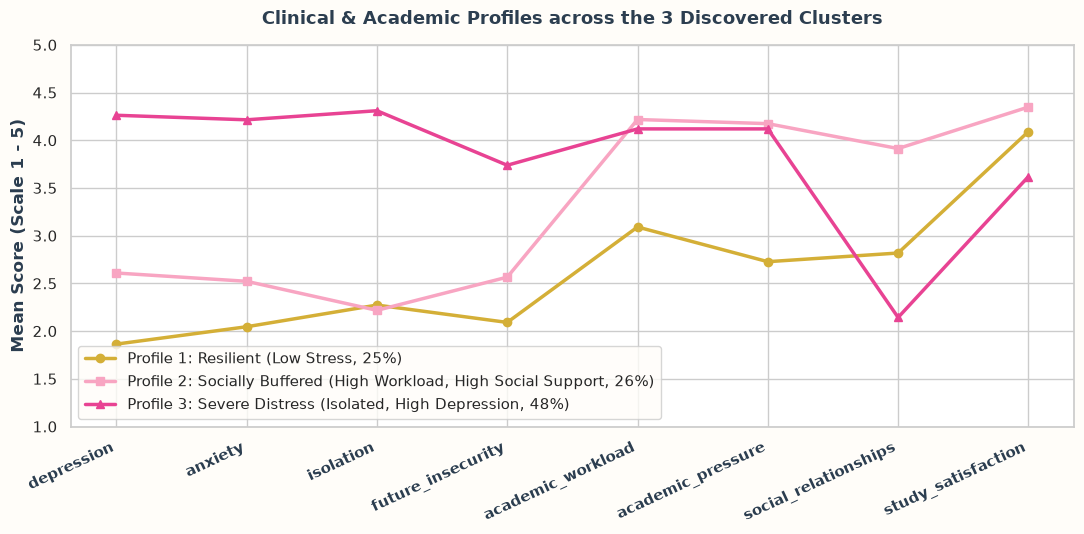

In [12]:
# Visualization 8: Multi-Metric Trajectories Across the 3 Profiles
features_to_plot = ['depression', 'anxiety', 'isolation', 'future_insecurity', 
                    'academic_workload', 'academic_pressure', 'social_relationships', 'study_satisfaction']

c_low = sorted_c[0]
c_mid = sorted_c[1]
c_high = sorted_c[2]

profile_means = df.groupby('cluster')[features_to_plot].mean()

plt.figure(figsize=(11, 5.5))
fig = plt.gcf()
fig.patch.set_facecolor(LIGHT_CREAM)

plt.plot(features_to_plot, profile_means.loc[c_low], marker='o', linewidth=2.5, color=GOLD, label='Profile 1: Resilient (Low Stress, 25%)')
plt.plot(features_to_plot, profile_means.loc[c_mid], marker='s', linewidth=2.5, color=SOFT_PINK, label='Profile 2: Socially Buffered (High Workload, High Social Support, 26%)')
plt.plot(features_to_plot, profile_means.loc[c_high], marker='^', linewidth=2.5, color=ROSE_PINK, label='Profile 3: Severe Distress (Isolated, High Depression, 48%)')

plt.title('Clinical & Academic Profiles across the 3 Discovered Clusters', weight='bold', fontsize=13, color=DARK_TEXT, pad=15)
plt.ylabel('Mean Score (Scale 1 - 5)', weight='bold', color=DARK_TEXT)
plt.xticks(rotation=25, ha='right', weight='bold', color=DARK_TEXT)
plt.ylim(1.0, 5.0)
plt.legend(frameon=True, facecolor=LIGHT_CREAM)
plt.tight_layout()
plt.show()


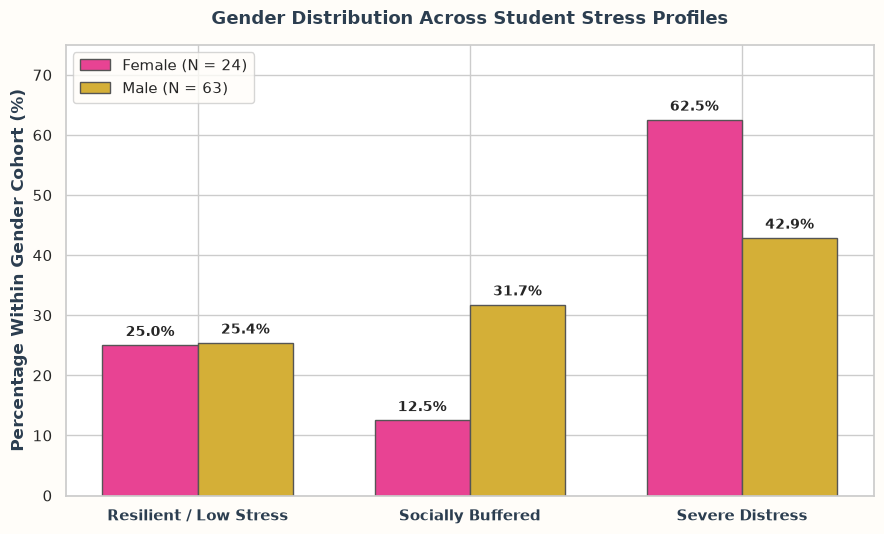

In [13]:
# Visualization 9: Gender Disparity Analysis
gender_crosstab = pd.crosstab(df['stress_profile'], df['gender'], normalize='columns') * 100

plt.figure(figsize=(9, 5.5))
fig = plt.gcf()
fig.patch.set_facecolor(LIGHT_CREAM)
x = np.arange(len(gender_crosstab.index))
width = 0.35

rects1 = plt.bar(x - width/2, gender_crosstab['Female'], width, label='Female (N = 24)', color=ROSE_PINK, edgecolor='#555555')
rects2 = plt.bar(x + width/2, gender_crosstab['Male'], width, label='Male (N = 63)', color=GOLD, edgecolor='#555555')

plt.title('Gender Distribution Across Student Stress Profiles', fontsize=13, weight='bold', color=DARK_TEXT, pad=15)
plt.ylabel('Percentage Within Gender Cohort (%)', weight='bold', color=DARK_TEXT)
plt.xticks(x, [i.split(':')[1].split('(')[0].strip() for i in gender_crosstab.index], weight='bold', color=DARK_TEXT)
plt.legend(frameon=True, facecolor=LIGHT_CREAM)

for rect in rects1:
    h = rect.get_height()
    plt.text(rect.get_x() + rect.get_width()/2, h + 1, f'{h:.1f}%', ha='center', va='bottom', weight='bold', fontsize=10)
for rect in rects2:
    h = rect.get_height()
    plt.text(rect.get_x() + rect.get_width()/2, h + 1, f'{h:.1f}%', ha='center', va='bottom', weight='bold', fontsize=10)

plt.ylim(0, 75)
plt.tight_layout()
plt.show()
